# Carbon Emission Dataset: Exploratory Data Analysis
Advanced Python Project 

Student: Abdullah Khalid Alsaleh

Libraries: Pandas, NumPy, Matplotlib, Seaborn, SciPy, statsmodels. The target variable is Carbon_Emission_tCO2e_TARGET.

## 1. Load and inspect data

In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
os.makedirs('figures', exist_ok=True)   # charts are saved here for the report
def save(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

DATA_PATH = 'carbon_emission_dataset_with_Industry.csv'
df = pd.read_csv(DATA_PATH)
TARGET = 'Carbon_Emission_tCO2e_TARGET'
print('Shape:', df.shape)
df.head()

Shape: (18250, 22)


,Company_ID,Date,Sector,Total_Energy_Consumption_kWh,Renewable_Energy_Consumption_kWh,NonRenewable_Energy_Consumption_kWh,Production_Output_Units,Supply_Chain_Transport_km,Supply_Chain_Transport_Mode,Raw_Material_Usage_kg,...,Carbon_Tax_USD,Process_Efficiency_Percent,Employment_Count,Public_Acceptance_Index,Carbon_Reduction_Strategy,Strategy_Implementation_Cost_USD,Expected_Carbon_Reduction_Percent,Expected_Renewable_Share_Percent,Social_Impact_Score,Industry_Sectors
0,C001,2024-01-01,Manufacturing,53751.61,12766.80,40984.81,3008.90,3814.12,Truck,51334.48,...,338.76,81.07,2128,0.77,Process Reengineering,188176.25,16.79,40.89,0.40,Steel Manufacturing
1,C001,2024-01-02,Manufacturing,170872.89,76733.84,94139.05,4062.25,1199.66,Air,17154.72,...,1073.13,69.26,855,0.77,Efficiency Upgrade,489246.31,12.57,58.19,0.86,Cement Production
2,C001,2024-01-03,Manufacturing,142777.96,75794.17,66983.79,6196.17,3670.57,Truck,56288.43,...,1390.41,90.33,3613,0.48,Carbon Tax Compliance,165061.64,12.11,68.14,0.79,Automotive Industry
3,C001,2024-01-04,Manufacturing,152532.15,20698.80,131833.35,6714.80,2903.63,Ship,21438.17,...,1942.56,79.49,3156,0.85,Efficiency Upgrade,191619.23,5.64,23.30,0.55,Logistics
4,C001,2024-01-05,Manufacturing,81647.43,46657.82,34989.61,8887.31,1916.05,Rail,37694.23,...,472.20,68.63,4915,0.47,Process Reengineering,459129.15,12.99,65.44,0.95,Steel Manufacturing


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18250 entries, 0 to 18249
Data columns (total 22 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Company_ID                           18250 non-null  str    
 1   Date                                 18250 non-null  str    
 2   Sector                               18250 non-null  str    
 3   Total_Energy_Consumption_kWh         18250 non-null  float64
 4   Renewable_Energy_Consumption_kWh     18250 non-null  float64
 5   NonRenewable_Energy_Consumption_kWh  18250 non-null  float64
 6   Production_Output_Units              18250 non-null  float64
 7   Supply_Chain_Transport_km            18250 non-null  float64
 8   Supply_Chain_Transport_Mode          18250 non-null  str    
 9   Raw_Material_Usage_kg                18250 non-null  float64
 10  Carbon_Emission_tCO2e_TARGET         18250 non-null  float64
 11  Energy_Cost_USD                      18

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Total_Energy_Consumption_kWh,18250.0,124776.987158,43106.624251,50008.7300,87326.36500,124728.53000,162042.9550,199988.9100
Renewable_Energy_Consumption_kWh,18250.0,43759.097184,24291.666951,5041.2000,24455.50250,38888.00500,59545.0250,119005.2600
NonRenewable_Energy_Consumption_kWh,18250.0,81017.889975,33957.852247,20483.2600,53738.54750,77007.82000,104085.3725,179431.0200
Production_Output_Units,18250.0,5538.963915,2597.576117,1000.4700,3273.99500,5556.40000,7802.0950,9999.7800
Supply_Chain_Transport_km,18250.0,2734.813587,1300.146027,500.3800,1609.12250,2735.02000,3862.7175,4999.8900
Raw_Material_Usage_kg,18250.0,44869.415215,20110.509566,10006.5000,27439.33500,44803.63000,62291.0275,79994.4600
Carbon_Emission_tCO2e_TARGET,18250.0,32.365099,14.482041,6.8149,20.96935,30.15455,41.5204,86.5718
Energy_Cost_USD,18250.0,10600.982042,4532.900551,2524.2000,6979.21000,10001.70000,13621.3850,23880.6900
Carbon_Tax_USD,18250.0,1129.541275,590.407029,155.7400,682.40750,1012.14500,1464.8475,4211.6000
Process_Efficiency_Percent,18250.0,77.623844,10.112534,60.0000,68.88000,77.66000,86.3175,95.0000


## 2. Data cleaning

In [4]:
# Missing values and duplicates
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum() > 0])
print('Total missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

Missing values per column:
Series([], dtype: int64)
Total missing values: 0
Duplicate rows: 0


There are no missing values and no duplicate rows, so nothing was removed or filled in. Next I fixed the data types.

In [5]:
# Adjust data types
df['Date'] = pd.to_datetime(df['Date'])
for c in ['Company_ID', 'Sector', 'Supply_Chain_Transport_Mode',
          'Carbon_Reduction_Strategy', 'Industry_Sectors']:
    df[c] = df[c].astype('category')
df = df.sort_values(['Date', 'Company_ID']).reset_index(drop=True)

# Sanity checks
diff = (df['Renewable_Energy_Consumption_kWh'] + df['NonRenewable_Energy_Consumption_kWh']
        - df['Total_Energy_Consumption_kWh']).abs().max()
print('Max |Renewable + NonRenewable - Total| =', round(diff, 6), '(energy columns are consistent)')
print('Date range:', df['Date'].min().date(), 'to', df['Date'].max().date(),
      '| companies:', df['Company_ID'].nunique(), '| days:', df['Date'].nunique())
df.dtypes

Max |Renewable + NonRenewable - Total| = 0.0 (energy columns are consistent)
Date range: 2024-01-01 to 2024-12-30 | companies: 50 | days: 365


Company_ID                                   category
Date                                   datetime64[us]
Sector                                       category
Total_Energy_Consumption_kWh                  float64
Renewable_Energy_Consumption_kWh              float64
NonRenewable_Energy_Consumption_kWh           float64
Production_Output_Units                       float64
Supply_Chain_Transport_km                     float64
Supply_Chain_Transport_Mode                  category
Raw_Material_Usage_kg                         float64
Carbon_Emission_tCO2e_TARGET                  float64
Energy_Cost_USD                               float64
Carbon_Tax_USD                                float64
Process_Efficiency_Percent                    float64
Employment_Count                                int64
Public_Acceptance_Index                       float64
Carbon_Reduction_Strategy                    category
Strategy_Implementation_Cost_USD              float64
Expected_Carbon_Reduction_Pe

Date is now a datetime column and the text columns are categories. Renewable plus non-renewable energy equals total energy in every row.

The file has no temperature column and no region column, so the temperature items in the project description cannot be done. I used Sector and Industry_Sectors for the group analysis instead.

## 3. Exploratory analysis

### 3.1 Basic statistics

In [6]:
cols = ['Total_Energy_Consumption_kWh', 'Renewable_Energy_Consumption_kWh',
        'NonRenewable_Energy_Consumption_kWh', 'Production_Output_Units',
        'Supply_Chain_Transport_km']
stats_tbl = df[cols].agg(['mean', 'median', 'max', 'min']).T.round(2)
stats_tbl

,mean,median,max,min
Total_Energy_Consumption_kWh,124776.99,124728.53,199988.91,50008.73
Renewable_Energy_Consumption_kWh,43759.10,38888.00,119005.26,5041.20
NonRenewable_Energy_Consumption_kWh,81017.89,77007.82,179431.02,20483.26
Production_Output_Units,5538.96,5556.40,9999.78,1000.47
Supply_Chain_Transport_km,2734.81,2735.02,4999.89,500.38


Renewable energy has a mean above its median, so it is skewed to the right. The other four are close to symmetric.

### 3.2 Distributions

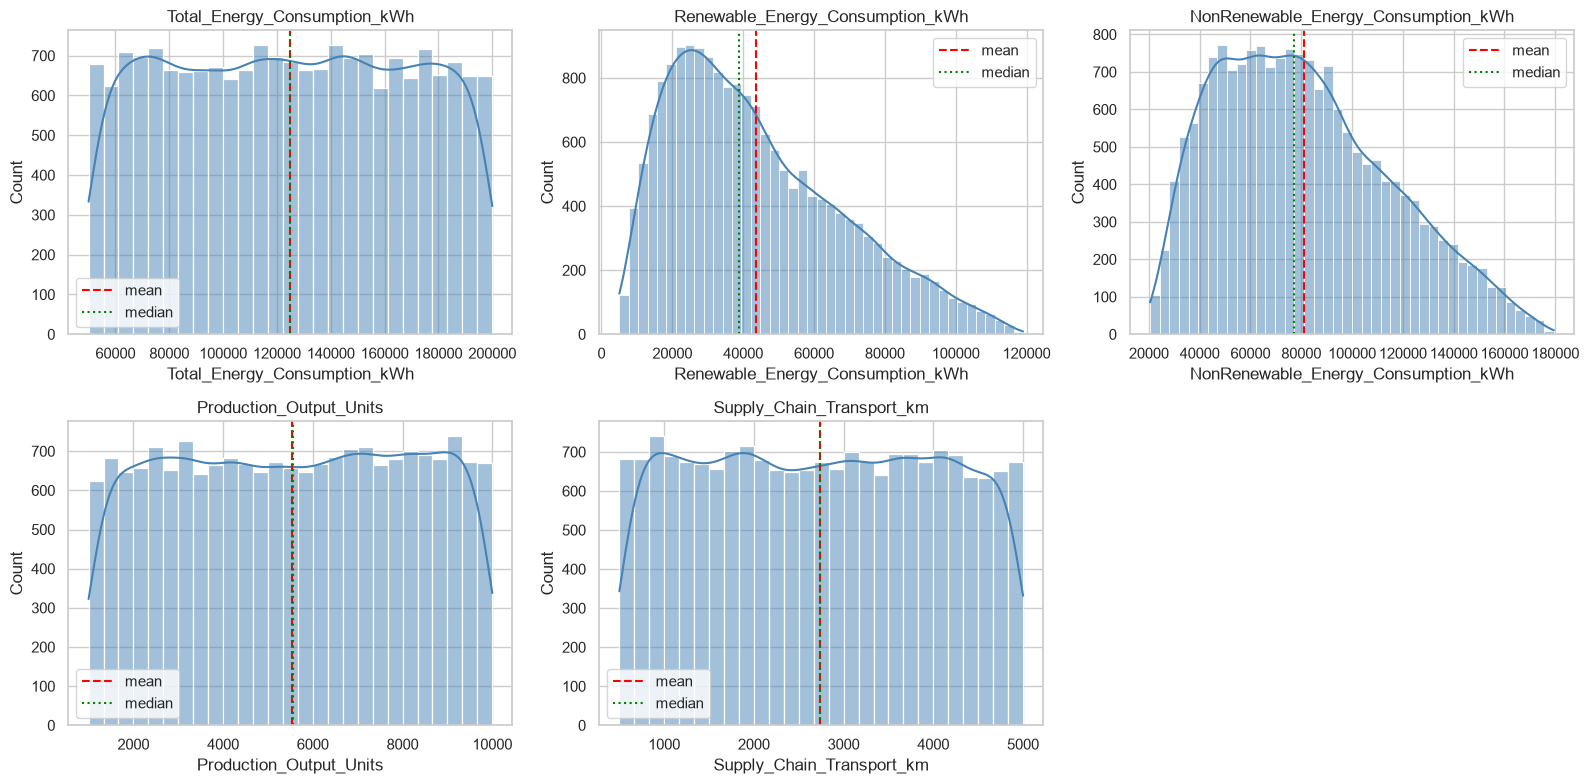

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, cols):
    sns.histplot(df[c], kde=True, ax=ax, color='steelblue')
    ax.axvline(df[c].mean(), color='red', ls='--', label='mean')
    ax.axvline(df[c].median(), color='green', ls=':', label='median')
    ax.set_title(c); ax.legend()
axes.flat[-1].axis('off')
plt.tight_layout(); save('01_distributions'); plt.show()

### 3.3 Frequency of each category

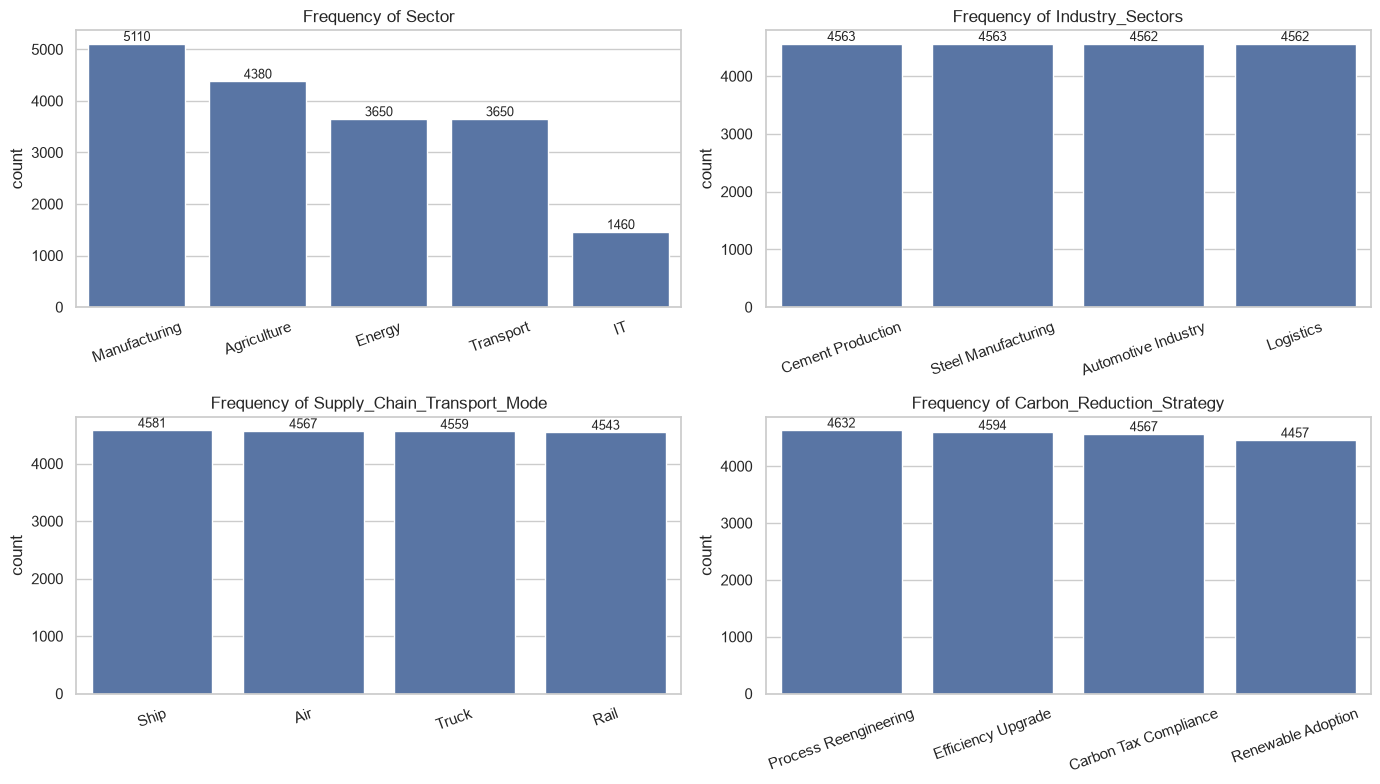

In [8]:
cats = ['Sector', 'Industry_Sectors', 'Supply_Chain_Transport_Mode', 'Carbon_Reduction_Strategy']
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, c in zip(axes.flat, cats):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax)
    ax.set_title(f'Frequency of {c}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
    for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); save('02_frequencies'); plt.show()

### 3.4 Energy over time (daily average of the 50 companies)

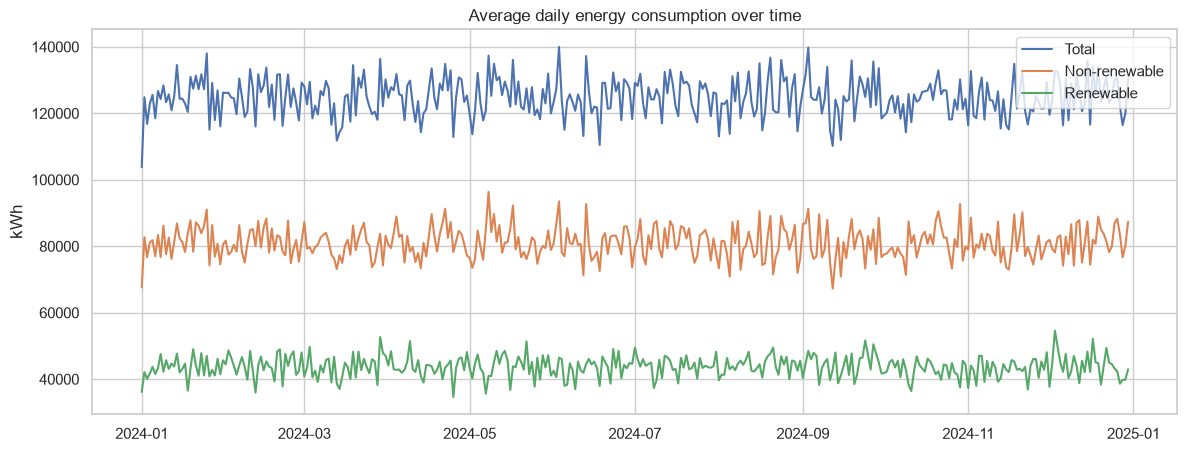

In [9]:
daily = df.groupby('Date').agg(
    total=('Total_Energy_Consumption_kWh', 'mean'),
    renewable=('Renewable_Energy_Consumption_kWh', 'mean'),
    nonrenewable=('NonRenewable_Energy_Consumption_kWh', 'mean'),
    emission=(TARGET, 'mean'))
plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily['total'], label='Total')
plt.plot(daily.index, daily['nonrenewable'], label='Non-renewable')
plt.plot(daily.index, daily['renewable'], label='Renewable')
plt.title('Average daily energy consumption over time'); plt.ylabel('kWh'); plt.legend(); save('03_energy_over_time'); plt.show()

### 3.5 Scatter plots

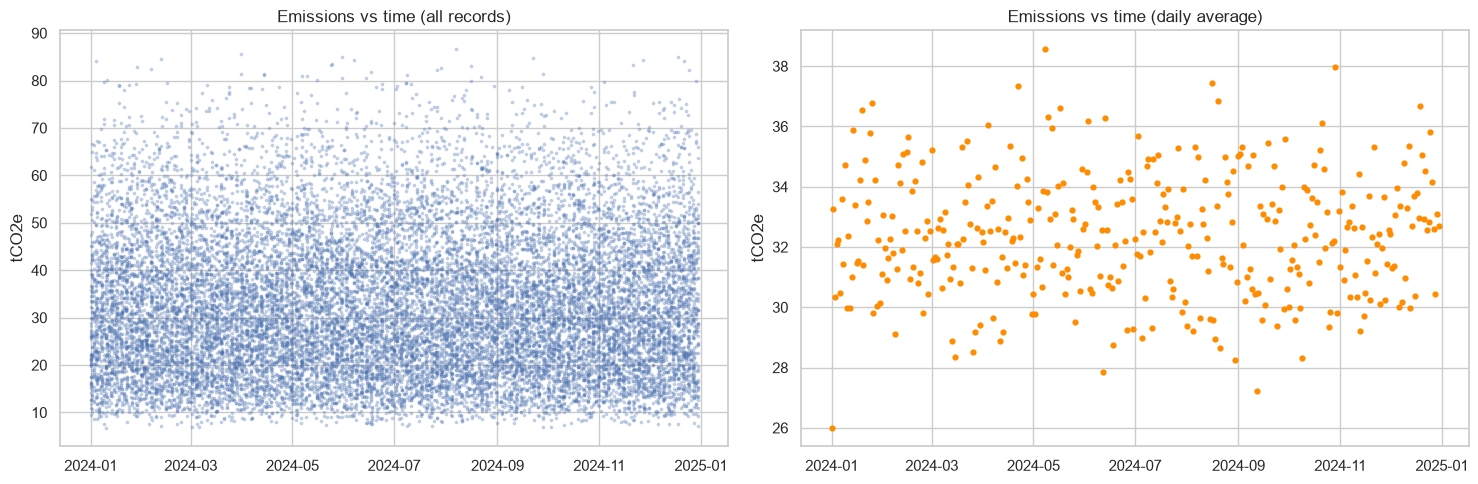

Emissions vs temperature: not possible, the dataset has no temperature column.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(df['Date'], df[TARGET], s=3, alpha=0.25)
axes[0].set_title('Emissions vs time (all records)'); axes[0].set_ylabel('tCO2e')
axes[1].scatter(daily.index, daily['emission'], s=12, color='darkorange')
axes[1].set_title('Emissions vs time (daily average)'); axes[1].set_ylabel('tCO2e')
plt.tight_layout(); save('04_emissions_vs_time'); plt.show()
print('Emissions vs temperature: not possible, the dataset has no temperature column.')

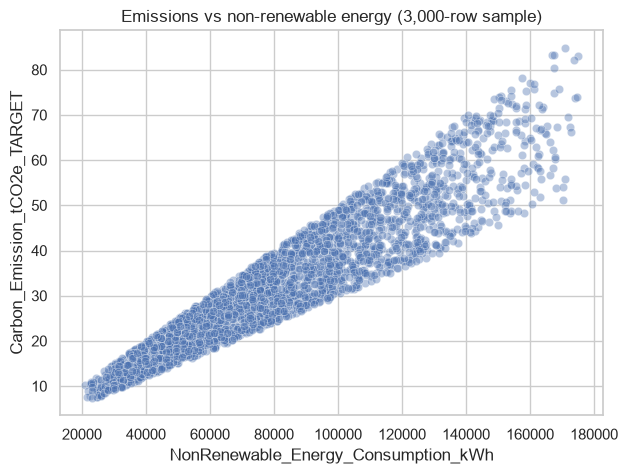

In [11]:
# Closest available alternative: emissions vs non-renewable energy
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df.sample(3000, random_state=1), x='NonRenewable_Energy_Consumption_kWh', y=TARGET, alpha=0.4)
plt.title('Emissions vs non-renewable energy (3,000-row sample)'); save('05_emissions_vs_nonrenewable'); plt.show()

Emissions vs temperature is not possible (no temperature column), so I plotted emissions against non-renewable energy instead.

## 4. Bivariate and multivariate analysis

### 4.1 Emissions vs energy sources

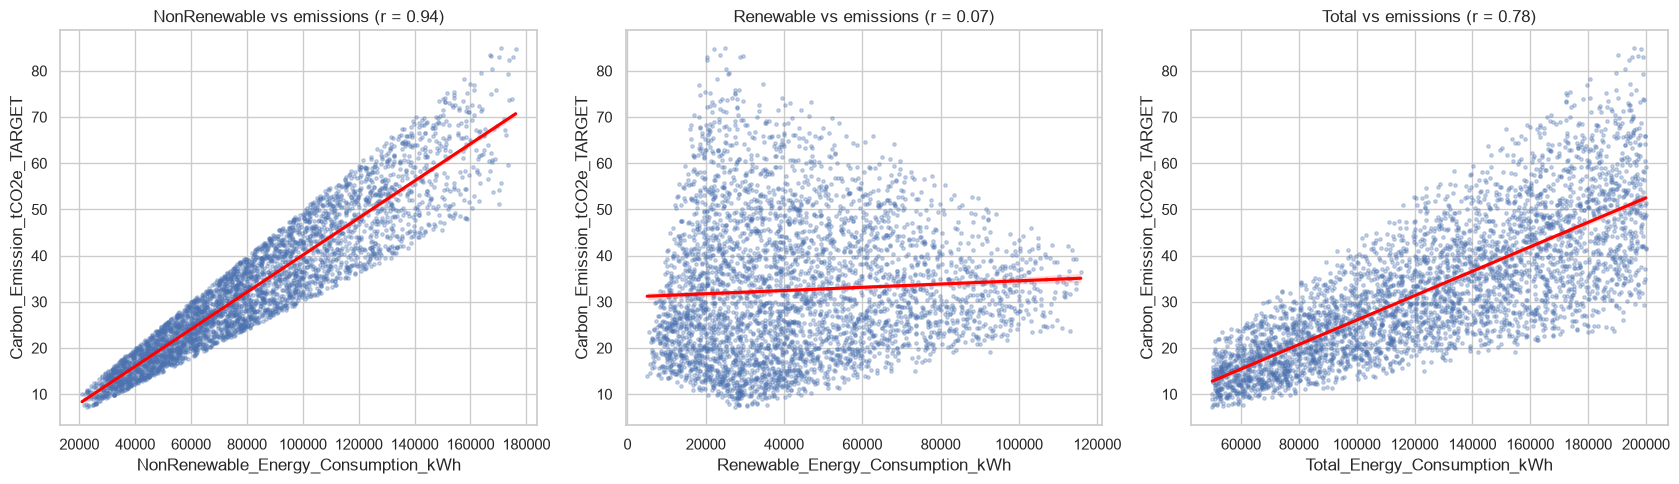

NonRenewable_Energy_Consumption_kWh    0.937
Renewable_Energy_Consumption_kWh       0.070
Total_Energy_Consumption_kWh           0.778
Carbon_Emission_tCO2e_TARGET           1.000
Name: Carbon_Emission_tCO2e_TARGET, dtype: float64


In [12]:
srcs = ['NonRenewable_Energy_Consumption_kWh', 'Renewable_Energy_Consumption_kWh', 'Total_Energy_Consumption_kWh']
s = df.sample(4000, random_state=1)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, c in zip(axes, srcs):
    sns.regplot(data=s, x=c, y=TARGET, ax=ax, scatter_kws={'s': 6, 'alpha': 0.3}, line_kws={'color': 'red'})
    ax.set_title(f'{c.split("_Energy")[0]} vs emissions (r = {df[c].corr(df[TARGET]):.2f})')
plt.tight_layout(); save('06_source_comparison'); plt.show()
print(df[srcs + [TARGET]].corr()[TARGET].round(3))

### 4.2 Correlation heatmap

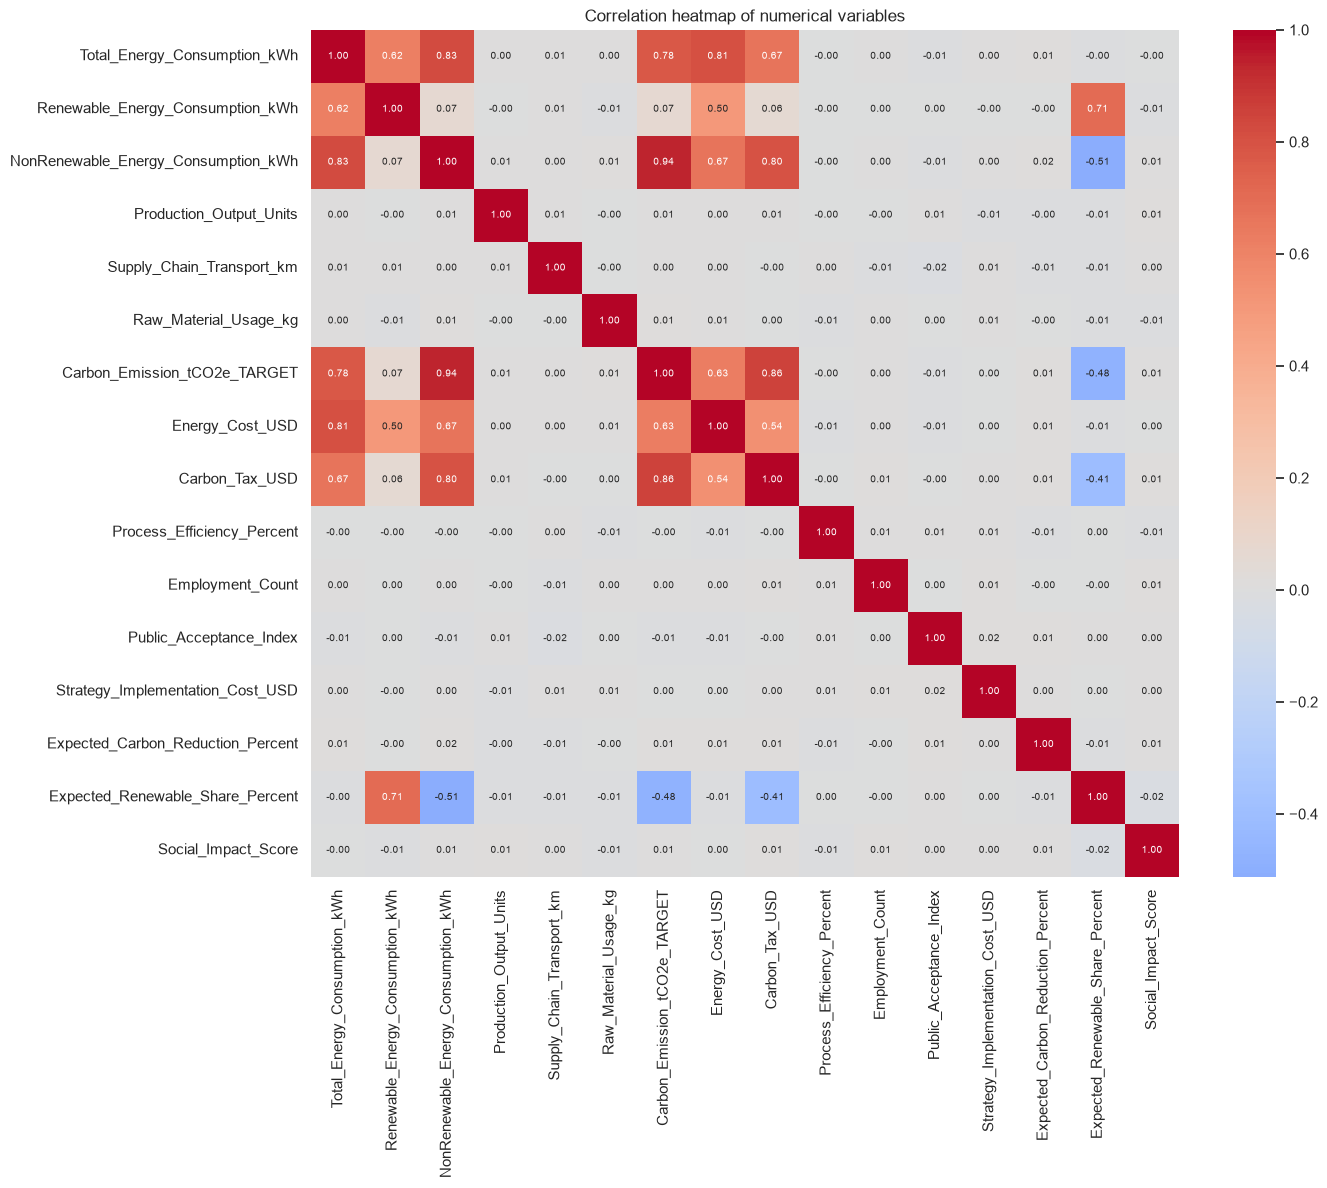

In [13]:
num = df.select_dtypes('number')
plt.figure(figsize=(14, 11))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation heatmap of numerical variables'); save('07_heatmap'); plt.show()

### 4.3 Box plot by industry

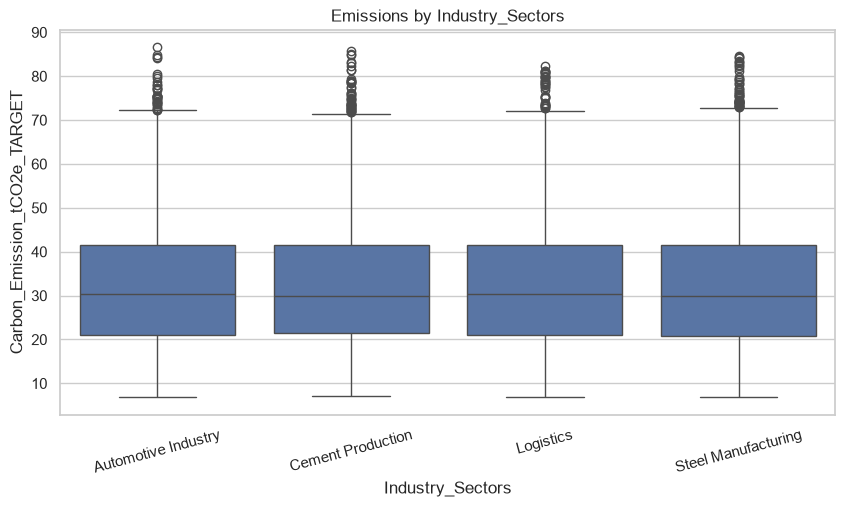

In [14]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Industry_Sectors', y=TARGET)
plt.title('Emissions by Industry_Sectors'); plt.xticks(rotation=15); save('08_boxplot_industry'); plt.show()

### 4.4 Pairplot

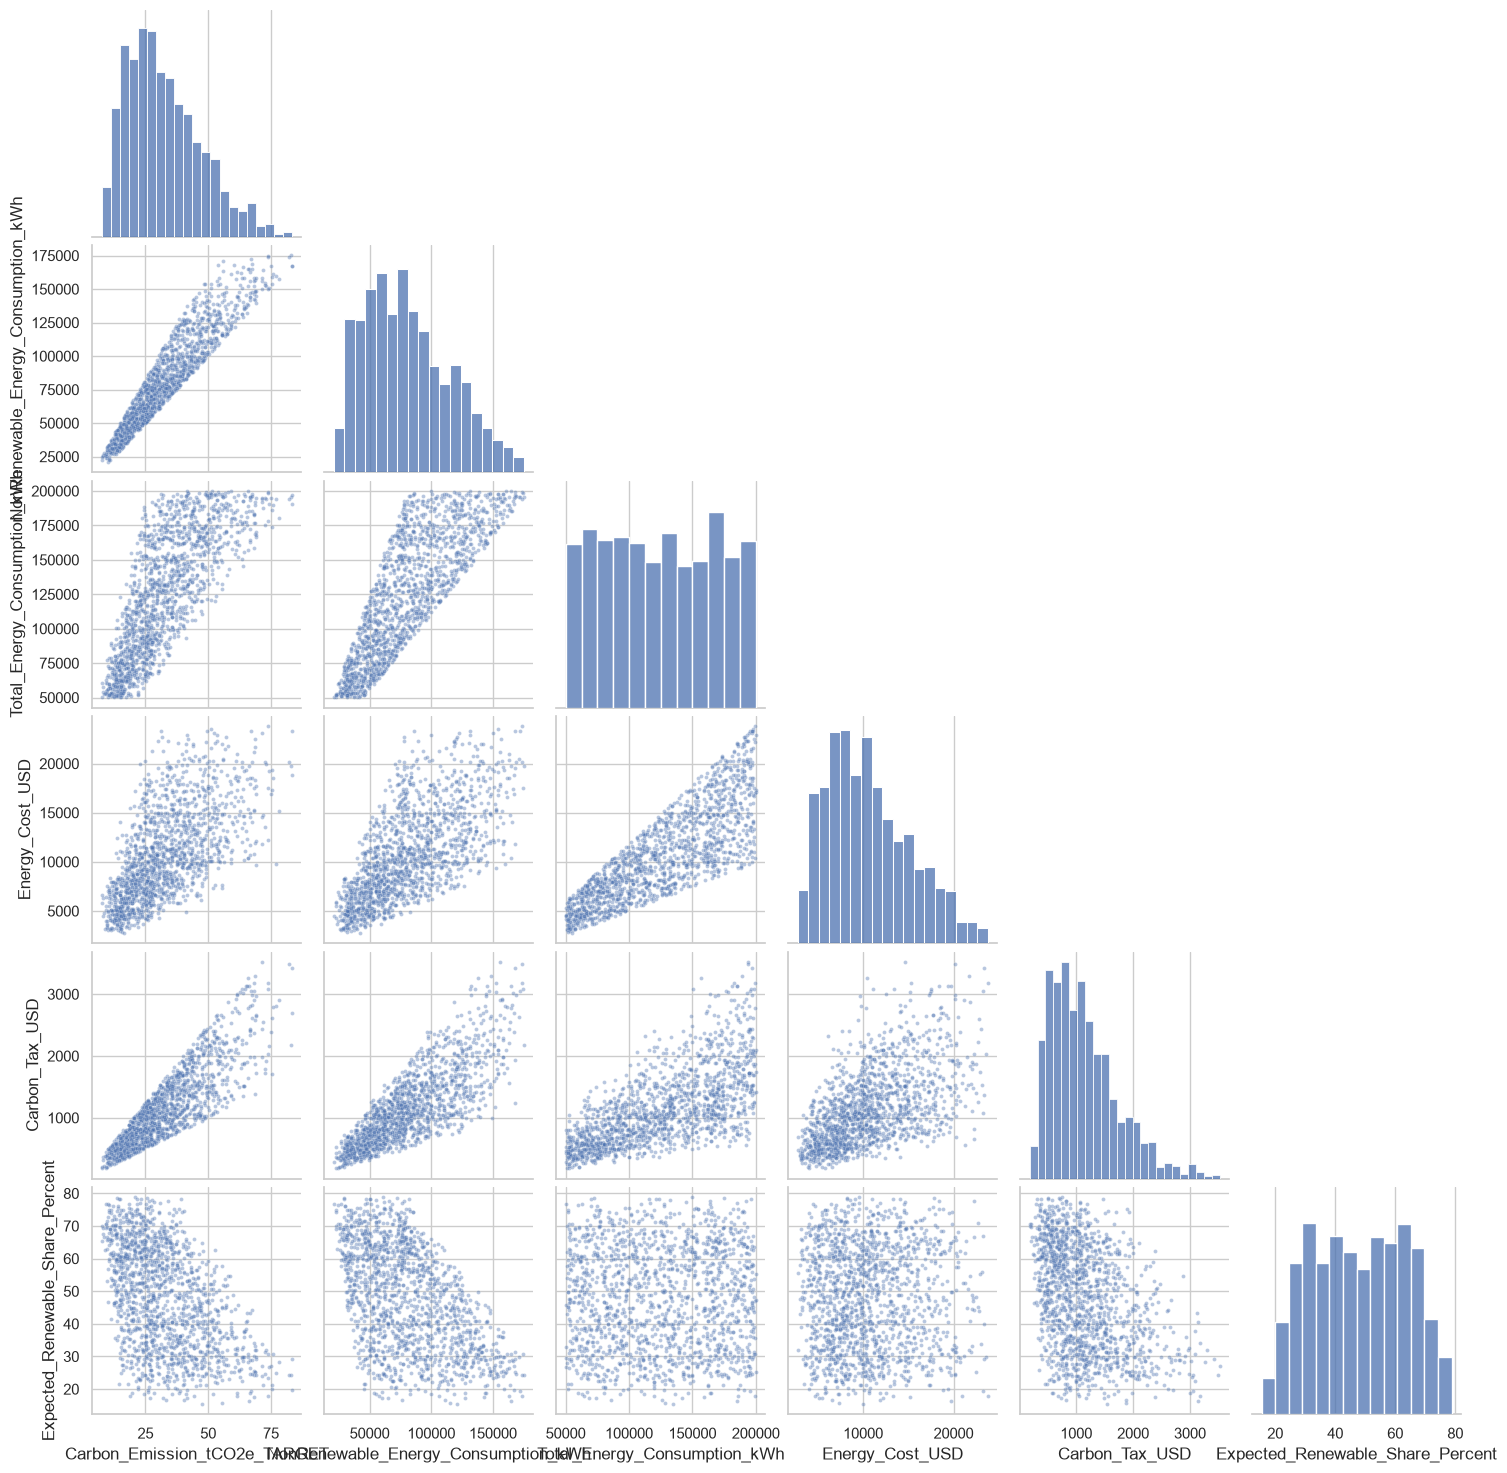

In [15]:
sel = [TARGET, 'NonRenewable_Energy_Consumption_kWh', 'Total_Energy_Consumption_kWh',
       'Energy_Cost_USD', 'Carbon_Tax_USD', 'Expected_Renewable_Share_Percent']
g = sns.pairplot(df[sel].sample(1500, random_state=1), corner=True, plot_kws={'s': 8, 'alpha': 0.4})
g.savefig('figures/09_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.5 Group analysis (by Sector and Industry)

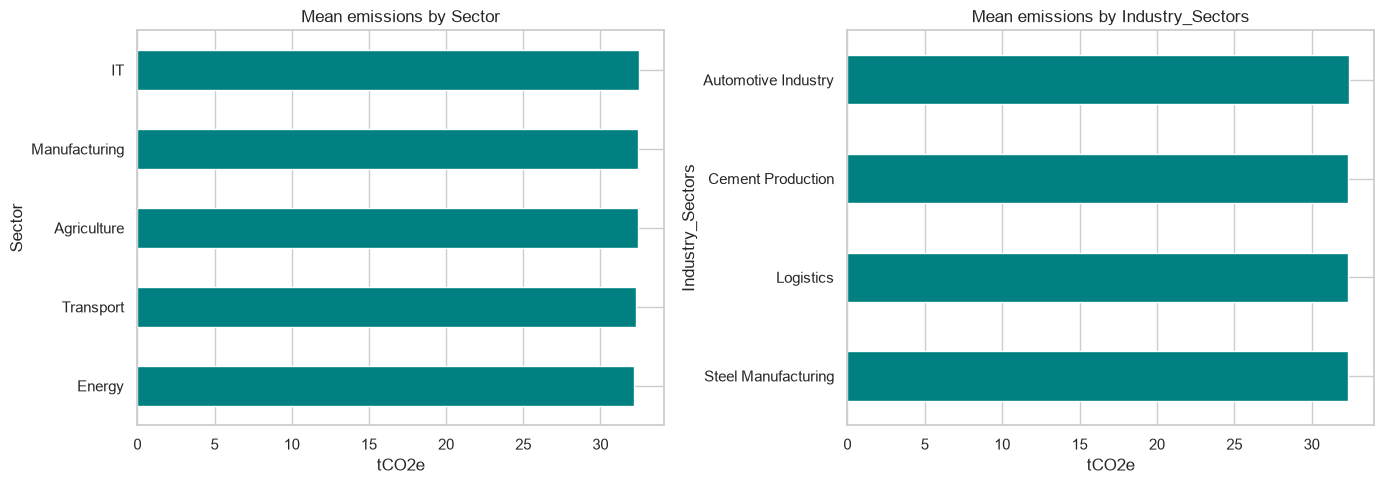

,mean,median,std
Sector,,,
Agriculture,32.41,30.30,14.53
Energy,32.17,29.91,14.78
IT,32.50,30.51,14.01
Manufacturing,32.45,30.29,14.29
Transport,32.34,29.89,14.58


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, g in zip(axes, ['Sector', 'Industry_Sectors']):
    m = df.groupby(g)[TARGET].mean().sort_values()
    m.plot.barh(ax=ax, color='teal'); ax.set_title(f'Mean emissions by {g}'); ax.set_xlabel('tCO2e')
plt.tight_layout(); save('10_group_means'); plt.show()
df.groupby('Sector')[TARGET].agg(['mean', 'median', 'std']).round(2)

## 5. Time series

2024-01-01 -> 2024-12-30 | n = 365


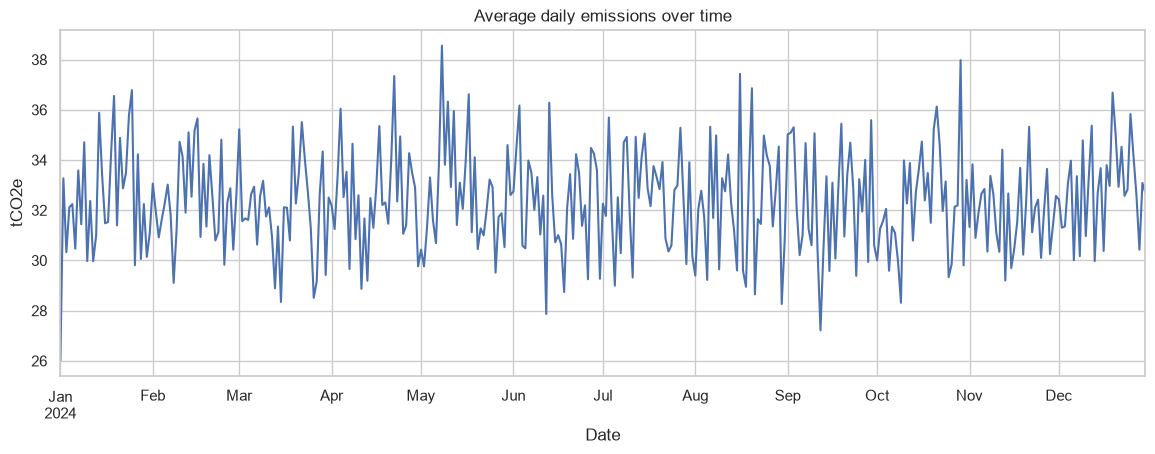

Temperature trend: not possible, the dataset has no temperature column.


In [17]:
ts = df.set_index('Date')
emis = ts[TARGET].resample('D').mean()   # daily average across the 50 companies
print(emis.index.min().date(), '->', emis.index.max().date(), '| n =', len(emis))
plt.figure(figsize=(14, 4.5))
emis.plot(); plt.title('Average daily emissions over time'); plt.ylabel('tCO2e'); save('11_daily_emissions'); plt.show()
print('Temperature trend: not possible, the dataset has no temperature column.')

### 5.1 Decomposition

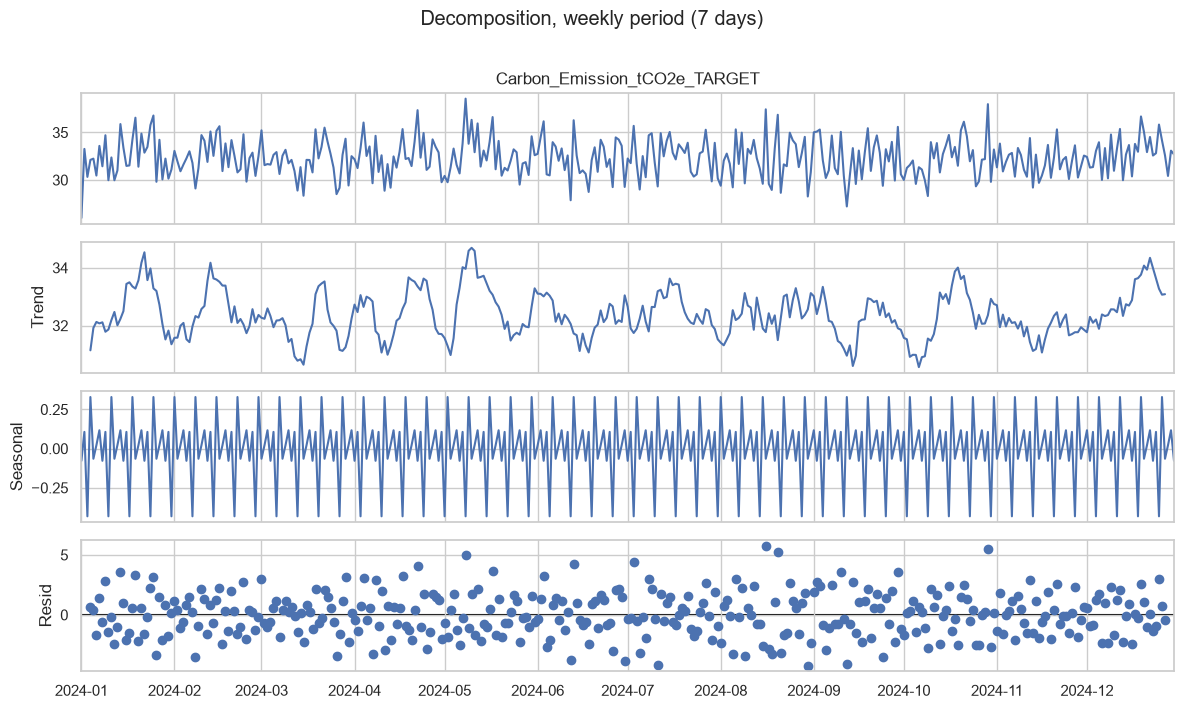

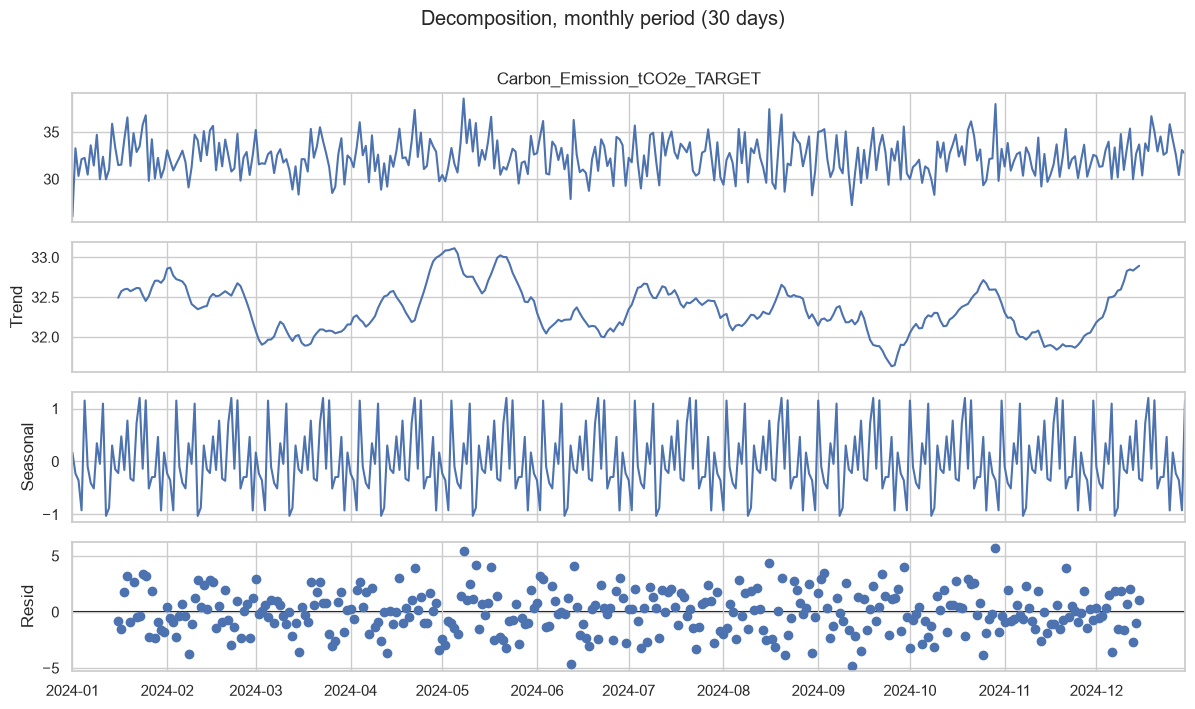

In [18]:
for p, name, fn in [(7, 'weekly', '12_decomp_weekly'), (30, 'monthly', '13_decomp_monthly')]:
    r = seasonal_decompose(emis, model='additive', period=p)
    fig = r.plot(); fig.set_size_inches(12, 7); fig.suptitle(f'Decomposition, {name} period ({p} days)', y=1.01)
    plt.tight_layout(); save(fn); plt.show()

The data covers one year only, so I used weekly (7 days) and monthly (30 days) periods. A yearly cycle needs at least two years.

### 5.2 Rolling statistics

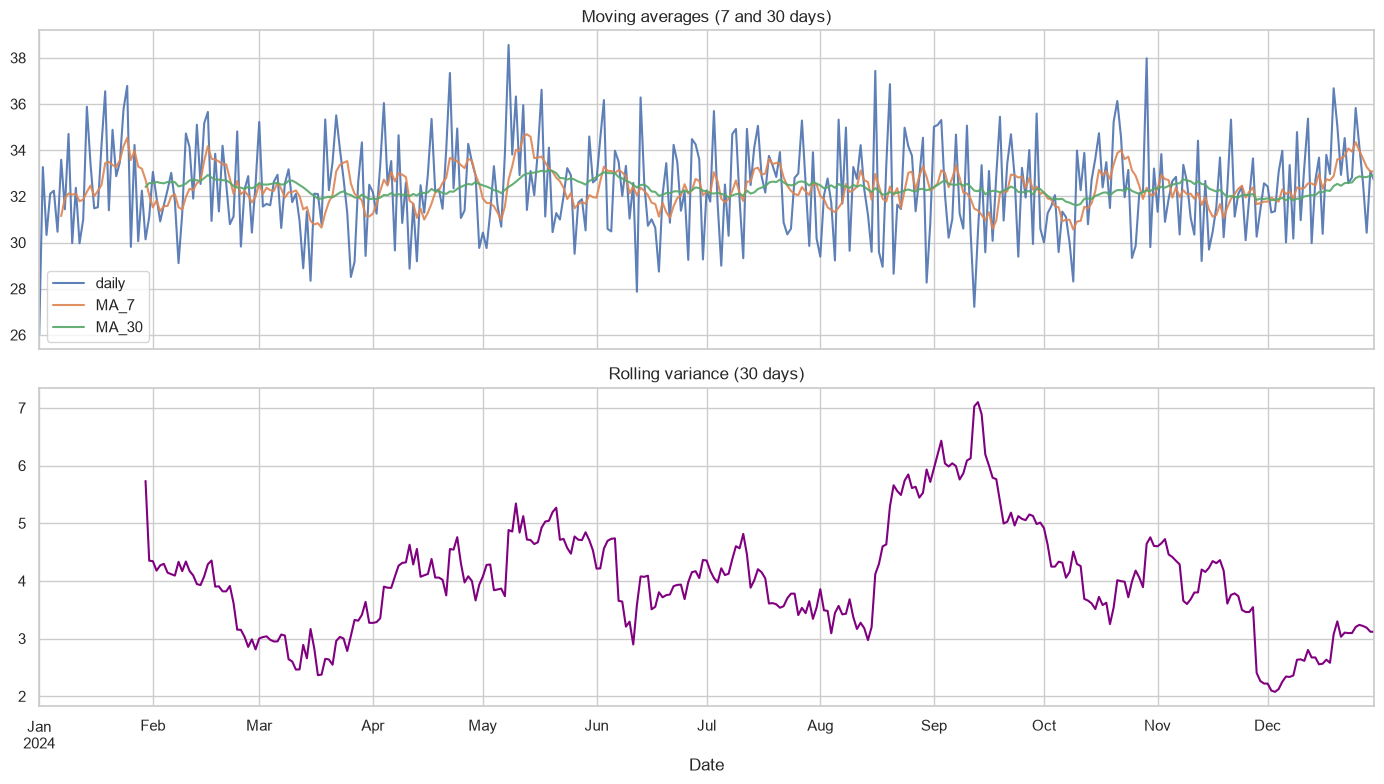

In [19]:
roll = pd.DataFrame({'daily': emis,
                     'MA_7': emis.rolling(7).mean(),
                     'MA_30': emis.rolling(30).mean()})
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
roll.plot(ax=axes[0], alpha=0.9); axes[0].set_title('Moving averages (7 and 30 days)')
emis.rolling(30).var().plot(ax=axes[1], color='purple'); axes[1].set_title('Rolling variance (30 days)')
plt.tight_layout(); save('14_rolling'); plt.show()

## 6. Questions

### Q1. Which sources have the highest variability?

In [20]:
var_cols = ['Renewable_Energy_Consumption_kWh', 'NonRenewable_Energy_Consumption_kWh', 'Production_Output_Units',
            'Total_Energy_Consumption_kWh', 'Supply_Chain_Transport_km', 'Raw_Material_Usage_kg', TARGET]
q1 = pd.DataFrame({'std': df[var_cols].std(), 'CV (std/mean)': df[var_cols].std() / df[var_cols].mean()}).round(3)
q1.sort_values('CV (std/mean)', ascending=False)

,std,CV (std/mean)
Renewable_Energy_Consumption_kWh,24291.667,0.555
Supply_Chain_Transport_km,1300.146,0.475
Production_Output_Units,2597.576,0.469
Raw_Material_Usage_kg,20110.510,0.448
Carbon_Emission_tCO2e_TARGET,14.482,0.447
NonRenewable_Energy_Consumption_kWh,33957.852,0.419
Total_Energy_Consumption_kWh,43106.624,0.345


Total and non-renewable energy have the biggest standard deviation because their values are the largest. Comparing with the coefficient of variation, renewable energy is the most variable (0.56). Emissions are at 0.45.

### Q2. Are emissions normally distributed?

Skewness: 0.666 | Excess kurtosis: -0.004
Shapiro-Wilk (5,000 sample): ShapiroResult(statistic=np.float64(0.9604428512025975), pvalue=np.float64(6.953500825423332e-35))
D'Agostino-Pearson (all rows): NormaltestResult(statistic=np.float64(1127.2941586600662), pvalue=np.float64(1.6262365065125561e-245))


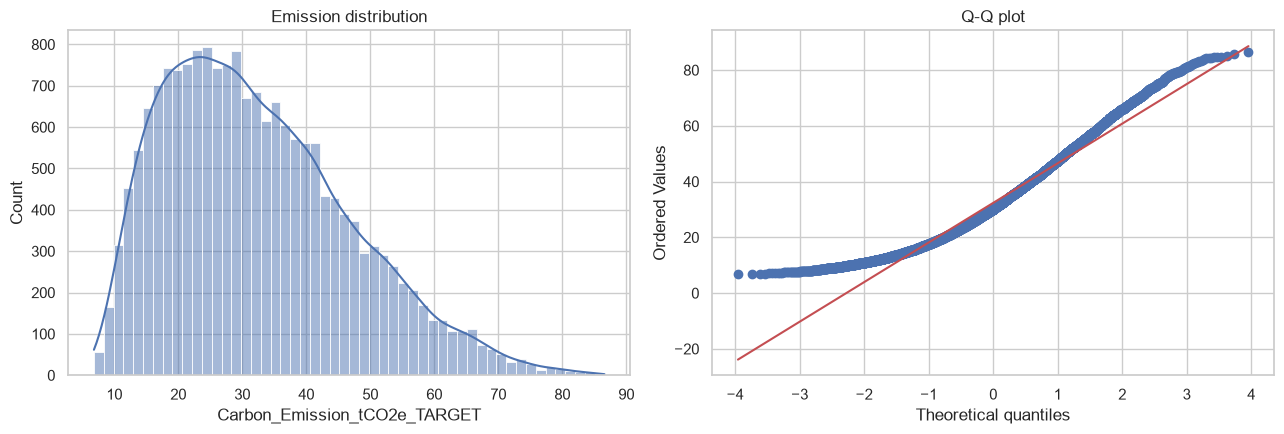

In [21]:
e = df[TARGET]
print('Skewness:', round(e.skew(), 3), '| Excess kurtosis:', round(e.kurt(), 3))
print('Shapiro-Wilk (5,000 sample):', stats.shapiro(e.sample(5000, random_state=1)))
print("D'Agostino-Pearson (all rows):", stats.normaltest(e))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(e, kde=True, ax=axes[0]); axes[0].set_title('Emission distribution')
stats.probplot(e, dist='norm', plot=axes[1]); axes[1].set_title('Q-Q plot')
plt.tight_layout(); save('15_q2_normality'); plt.show()

No. Skewness is 0.67 and both tests give p-values far below 0.05. The Q-Q plot bends away from the line at both ends. 155 rows are outliers by the IQR rule.

### Q3. Which variables are strongly correlated?

In [22]:
corr = num.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('r').reset_index().rename(columns={'level_0': 'var1', 'level_1': 'var2'}))
strong = pairs[pairs['r'].abs() >= 0.6].sort_values('r', key=abs, ascending=False)
display(strong.round(2))
print('\nCorrelation with target:'); print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).head(6))
print(corr[TARGET].drop(TARGET).sort_values().round(3).head(2))

,var1,var2,r
38,NonRenewable_Energy_Consumption_kWh,Carbon_Emission_tCO2e_TARGET,0.94
104,Carbon_Emission_tCO2e_TARGET,Carbon_Tax_USD,0.86
2,Total_Energy_Consumption_kWh,NonRenewable_Energy_Consumption_kWh,0.83
7,Total_Energy_Consumption_kWh,Energy_Cost_USD,0.81
40,NonRenewable_Energy_Consumption_kWh,Carbon_Tax_USD,0.80
6,Total_Energy_Consumption_kWh,Carbon_Emission_tCO2e_TARGET,0.78
30,Renewable_Energy_Consumption_kWh,Expected_Renewable_Share_Percent,0.71
39,NonRenewable_Energy_Consumption_kWh,Energy_Cost_USD,0.67
8,Total_Energy_Consumption_kWh,Carbon_Tax_USD,0.67
103,Carbon_Emission_tCO2e_TARGET,Energy_Cost_USD,0.63



Correlation with target:
NonRenewable_Energy_Consumption_kWh    0.937
Carbon_Tax_USD                         0.856
Total_Energy_Consumption_kWh           0.778
Energy_Cost_USD                        0.626
Renewable_Energy_Consumption_kWh       0.070
Expected_Carbon_Reduction_Percent      0.010
Name: Carbon_Emission_tCO2e_TARGET, dtype: float64
Expected_Renewable_Share_Percent   -0.477
Public_Acceptance_Index            -0.006
Name: Carbon_Emission_tCO2e_TARGET, dtype: float64


Emissions are strongly correlated with non-renewable energy (0.94), carbon tax (0.86), total energy (0.78) and energy cost (0.63). Expected renewable share is negative (-0.48). Renewable energy is almost not related (0.07). Carbon tax and energy cost come from emissions and energy, so they should not be used to predict emissions.

### Q4. Is there a trend in emissions?

Slope = 0.00010 tCO2e/day | R^2 = 0.00003 | p-value = 0.919
Spearman: SignificanceResult(statistic=np.float64(0.006485811516128159), pvalue=np.float64(0.90172104834562))


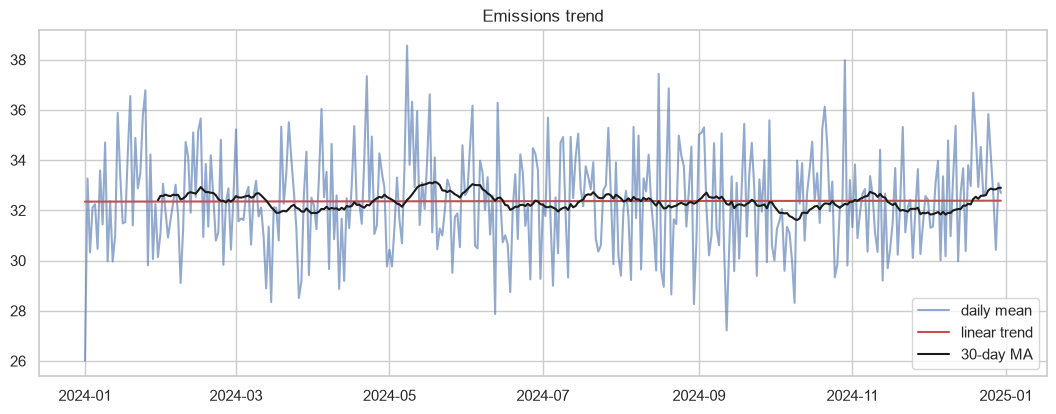

In [23]:
x = np.arange(len(emis))
lr = stats.linregress(x, emis.values)
print(f'Slope = {lr.slope:.5f} tCO2e/day | R^2 = {lr.rvalue**2:.5f} | p-value = {lr.pvalue:.3f}')
print('Spearman:', stats.spearmanr(x, emis.values))
plt.figure(figsize=(13, 4.5))
plt.plot(emis.index, emis.values, alpha=0.6, label='daily mean')
plt.plot(emis.index, lr.intercept + lr.slope * x, 'r', label='linear trend')
plt.plot(emis.index, emis.rolling(30).mean(), 'k', label='30-day MA'); plt.legend()
plt.title('Emissions trend'); save('16_q4_trend'); plt.show()

No. The slope is 0.0001 tCO2e per day with p = 0.92, which is not different from zero.

### Q5. Are there seasonal patterns?

Mean by day of week:
dow
0    32.21
1    32.52
2    31.93
3    32.70
4    32.33
5    32.36
6    32.52

Kruskal-Wallis day of week : KruskalResult(statistic=np.float64(5.9465083958662035), pvalue=np.float64(0.42920888892367726))
Kruskal-Wallis month       : KruskalResult(statistic=np.float64(6.568550852179214), pvalue=np.float64(0.8328703262006675))


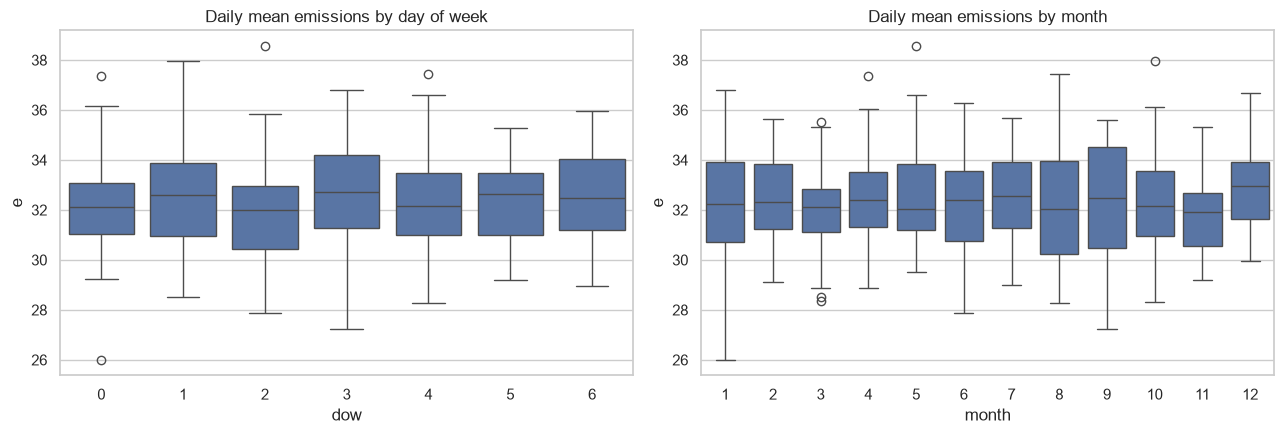

Seasonal strength (period 7): 0.014
Seasonal strength (period 30): 0.100


In [24]:
d = emis.to_frame('e')
d['dow'] = d.index.dayofweek; d['month'] = d.index.month
print('Mean by day of week:'); print(d.groupby('dow')['e'].mean().round(2).to_string())
print('\nKruskal-Wallis day of week :', stats.kruskal(*[g['e'].values for _, g in d.groupby('dow')]))
print('Kruskal-Wallis month       :', stats.kruskal(*[g['e'].values for _, g in d.groupby('month')]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=d, x='dow', y='e', ax=axes[0]); axes[0].set_title('Daily mean emissions by day of week')
sns.boxplot(data=d, x='month', y='e', ax=axes[1]); axes[1].set_title('Daily mean emissions by month')
plt.tight_layout(); save('17_q5_seasonality'); plt.show()
for p in (7, 30):
    r = seasonal_decompose(emis, period=p)
    fs = max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())
    print(f'Seasonal strength (period {p}): {fs:.3f}')

No. Averages by weekday and by month are almost the same (Kruskal-Wallis p = 0.43 and 0.83) and the seasonal strength is close to zero. With one year of data, yearly seasonality cannot be tested.

## Conclusion
- 18,250 rows, no missing values, no duplicates.
- Emissions depend mainly on non-renewable energy (correlation 0.94).
- Emissions are right-skewed and not normal.
- No trend and no seasonality in 2024. Sectors and industries have almost the same average.
- Limits: no temperature or region column, and only one year of data.